# BÀI LAB 2: XỬ LÝ ẢNH SỐ — TOÁN TỬ ĐIỂM ẢNH VÀ CÁC BỘ LỌC KHÔNG GIAN

## Mục tiêu nghiên cứu
Ảnh thu nhận có thể thiếu sáng, tương phản thấp, chứa nhiễu hoặc có đường biên khó nhận biết. Lab nghiên cứu cách biến đổi giá trị pixel và khai thác vùng lân cận để giải quyết các vấn đề này trong miền không gian.

| Phần | Vấn đề | Phương pháp |
|---|---|---|
| I. Toán tử điểm ảnh | Cường độ chưa phù hợp, khó tách đối tượng | Brightness, Contrast, Negative, Thresholding |
| II. Lọc tuyến tính | Nhiễu, ảnh thiếu sắc nét | Mean, Gaussian, Sharpening |
| III. Bài tập nâng cao | Trích xuất biên, thiết kế bộ lọc, lựa chọn phương pháp khử nhiễu | Sobel, Prewitt, Custom Kernel, Median, Bilateral |

## Chuẩn bị dữ liệu và công cụ quan sát
Ảnh số là ma trận mẫu rời rạc; ảnh xám có một giá trị cường độ tại mỗi vị trí, ảnh RGB có ba thành phần màu. Với `uint8`, mỗi thành phần có 256 mức từ 0 đến 255. Sampling rời rạc hóa vị trí; Quantization rời rạc hóa cường độ.

OpenCV đọc ảnh BGR, notebook chuyển sang RGB để hiển thị và tạo ảnh xám để xử lý. Histogram cường độ đếm số pixel theo mức sáng; histogram gradient đếm số pixel theo độ lớn biến thiên cục bộ. Hai histogram không lưu vị trí không gian của pixel.


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

# Nhập đường dẫn từ bàn phím
path = input("Nhập đường dẫn tới file của bạn: ").strip()


print(f"Đường dẫn bạn vừa nhập: {path}")

imgRGB = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
imgGray = cv2.cvtColor(imgRGB, cv2.COLOR_RGB2GRAY)

def displayIMG(titles_list, images_list, w = 10, h = 6, histogram = False, forceGray = False):
    """
    Hàm hiển thị danh sách nhiều ảnh cạnh nhau một cách linh hoạt.
    
    Args:
        titles (list): Danh sách tiêu đề cho từng ảnh.
        images (list): Danh sách các mảng numpy chứa dữ liệu ảnh.
        w (int): Chiều rộng khung hình chung.
        h (int): Chiều cao khung hình chung.
        histogram (bool): Hiển thị thêm histogram (nếu cần).
        force_gray (bool): Buộc hiển thị tất cả dưới dạng ảnh xám (nếu cần thiết).
    """
    colum = len(images_list)
    # Chặn và cảnh báo 2 trường hợp đầu vào rỗng và số lượng ảnh và title không khớp nhau 
    if colum == 0:
        print("Không có hình ảnh đầu vào!")
        return
    elif len(titles_list) != colum:
        print("Số lượng title và ảnh không khớp nhau!")
        return
    
    row = 2 if histogram else 1
    fig, axes = plt.subplots(row, colum, figsize=(w, h), squeeze=False)
    colors = ('r', 'g', 'b') # Định nghĩa màu vẽ histogram theo chuẩn ảnh RGB của plt

    for i in range(colum):
        current_img = images_list[i]
        # Xử lý None trong list
        if current_img is None:
            # Xử lý khi gặp None: Hiển thị khung trống kèm thông báo lỗi
            axes[0, i].text(0.5, 0.5, "Lỗi: đọc lại vui lòng đọc lại [Cảnh báo]", 
                            color='red', fontsize=10, ha='center', va='center', 
                            transform=axes[0, i].transAxes)
            axes[0, i].set_title(titles_list[i], fontsize=12, fontweight='bold')
            axes[0, i].axis("off")
            
            # Nếu có hàng histogram ở dưới, cũng tắt luôn để tránh lỗi vẽ
            if histogram:
                axes[1, i].text(0.5, 0.5, "N/A", color='gray', fontsize=10, ha='center', va='center', transform=axes[1, i].transAxes)
                axes[1, i].axis("off")
            continue # Chuyển sang cột tiếp theo
        # --- HÀNG 1: HIỂN THỊ ẢNH ---
        if forceGray:
            # hiển thị ảnh xám
            axes[0, i].imshow(current_img, cmap="gray")
        else:
            # hiển thị ảnh màu 3 kênh RGB tự động hiển thị chuẩn
            axes[0, i].imshow(current_img)
        axes[0, i].set_title(titles_list[i], fontsize=12, fontweight='bold')
        axes[0, i].axis("off")

        if histogram:
            # --- HÀNG 2: HIỂN THỊ HISTOGRAM TƯƠNG ỨNG ---
            # Tách các kênh màu của ảnh hiện tại để vẽ histogram
            if forceGray:
                hist = cv2.calcHist([current_img], [0], None, [256], [0, 256])
                axes[1, i].plot(hist, color="gray", alpha=0.8)
            else:
                for c, col in enumerate(colors):
                    # Tính toán histogram cho từng kênh màu R, G, B
                    hist = cv2.calcHist([current_img], [c], None, [256], [0, 256])
                    axes[1, i].plot(hist, color=col, alpha=0.8)
                
            axes[1, i].set_xlim([0, 256])
            axes[1, i].grid(True, linestyle='--', alpha=0.5)
            
            # Gắn nhãn cho trục của cột đầu tiên cho gọn đồ thị
            if i == 0:
                axes[1, i].set_ylabel("Tần suất (Số lượng)")
            axes[1, i].set_xlabel("Giá trị Pixel")
            axes[1, i].set_title(f"Histogram {titles_list[i]}", fontsize=10)

    plt.tight_layout()
    plt.show()


def show_gradient_histogram(img, title=""):
    """
    Hiển thị Histogram Gradient để phân tích độ sắc nét của ảnh.

    Args:
        img: Ảnh đầu vào dạng NumPy array (BGR hoặc Grayscale).

    
    """

    if img is None:
        raise ValueError("Ảnh đầu vào không hợp lệ!")

    # 1. Chuyển ảnh màu sang Grayscale
    if len(img.shape) == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img.copy()

    # 2. Tính Gradient theo hai hướng X và Y
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    # 3. Tính độ lớn Gradient
    magnitude = cv2.magnitude(gx, gy)

    # 4. Tính Histogram
    hist, bins = np.histogram(
        magnitude.ravel(),
        bins=256,
        range=(0, 1443)
    )

    # 5. Hiển thị Histogram
    plt.figure(figsize=(9, 4))
    plt.plot(bins[:-1], hist)
    plt.title(f"{title} Histogram Gradient Magnitude")
    plt.xlabel("Gradient Magnitude")
    plt.ylabel("Number of Pixels")
    plt.xlim(0, 1443)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    








Đường dẫn bạn vừa nhập: C:\Users\TAN LOC\Desktop\CV_Lab-1-5-\Lab2\data\input\images.jpg


## I. TOÁN TỬ ĐIỂM ẢNH (POINT OPERATORS)

## 1–2. Điều chỉnh độ sáng và độ tương phản

### 1. Vấn đề cần giải quyết
Ảnh thiếu sáng hoặc có các mức sáng tối quá gần nhau khiến chi tiết khó phân biệt. Cần điều chỉnh phân bố cường độ mà không thay đổi vị trí pixel.

### 2. Kiến thức nền tảng
Pixel intensity, bit depth, dynamic range và histogram. Toán tử điểm ảnh có dạng $g(x,y)=T(f(x,y))$; đầu ra phụ thuộc pixel tương ứng, không phụ thuộc vùng lân cận. Hàm $T$ có thể tuyến tính, affine hoặc phi tuyến.

### 3. Định nghĩa và bản chất
Brightness dịch chuyển cường độ; contrast scaling thay đổi khoảng cách giữa các mức cường độ.

### 4. Lý do lựa chọn
Biến đổi affine đơn giản, dễ điều chỉnh và có thể vector hóa trên toàn ma trận.

### 5. Nguyên lý và luồng xử lý
$$g(x,y)=\operatorname{clip}(\alpha f(x,y)+\beta,0,255)$$
$\alpha>0$ là hệ số tương phản, $\beta$ là độ dịch sáng. Ví dụ pixel 100 với $\alpha=1.5,\beta=50$ cho 200. Nhân với $\alpha$ cũng có thể đổi độ sáng trung bình; clipping có thể làm mất chi tiết.

**Input:** ảnh RGB hoặc xám, alpha, beta. **Process:** chuyển float32, nhân/cộng, clipping, chuyển uint8. **Output:** ảnh cùng kích thước.

### 6. Ứng dụng và điều kiện sử dụng
Tiền xử lý ảnh thiếu sáng hoặc tương phản thấp; chọn tham số dựa trên histogram và quan sát vùng bão hòa.

### 8. Triển khai

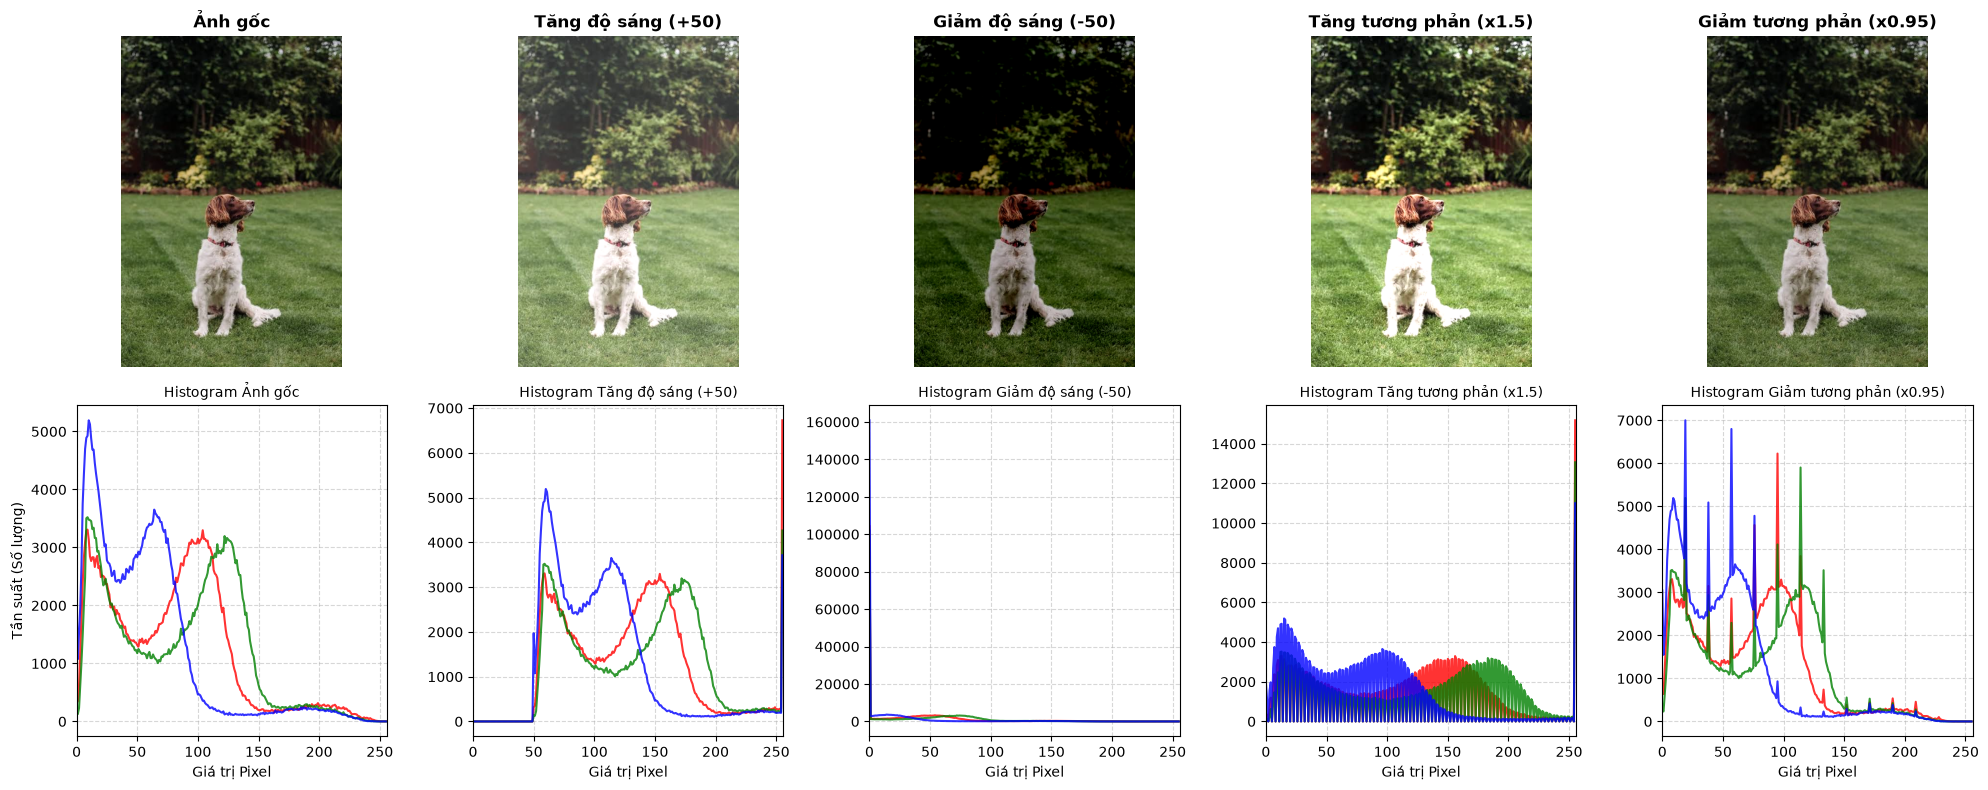

In [2]:
def lightAndContrast(img, light=0, contrast=1.0):
  """
  Điều chỉnh độ sáng và độ tương phản của ảnh sử dụng phép toán vector hóa.
  
  Args:
      img (np.ndarray): Ảnh đầu vào (có thể là ảnh xám 2D hoặc ảnh màu RGB/BGR 3D).
      light (int/float): Giá trị cộng thêm để thay đổi độ sáng (-255 đến 255).
      contrast (float): Hệ số nhân để thay đổi độ tương phản (> 0).
      
  Returns:
      np.ndarray: Ảnh sau khi biến đổi (kiểu uint8).
  """
  # Chuyển sang float32 để tránh tràn số khi nhân/cộng, sau đó áp dụng biến đổi tuyến tính
  img_processed = contrast * img.astype(np.float32) + light
  
  # Giới hạn giá trị trong khoảng [0, 255] để mô phỏng chính xác dải màu uint8
  result = np.clip(img_processed, 0, 255)
  
  return result.astype(np.uint8)

# Tạo danh sách 5 ảnh xử lý
images_list = [
    imgRGB,                                       # 0. Ảnh gốc
    lightAndContrast(imgRGB, light=50),           # 1. Tăng độ sáng
    lightAndContrast(imgRGB, light=-50),          # 2. Giảm độ sáng
    lightAndContrast(imgRGB, contrast=1.5),       # 3. Tăng độ tương phản
    lightAndContrast(imgRGB, contrast=0.95)       # 4. Giảm độ tương phản
]

titles_list = [
    "Ảnh gốc",
    "Tăng độ sáng (+50)",
    "Giảm độ sáng (-50)",
    "Tăng tương phản (x1.5)",
    "Giảm tương phản (x0.95)"
]

displayIMG(titles_list, images_list, 20, 8, True)



### 9. Đánh giá thực nghiệm

Histogram dịch theo beta trước clipping; alpha làm thay đổi khoảng cách mức sáng. Kiểm tra tích tụ tại 0/255 để nhận biết saturation. Không suy ra chất lượng chỉ từ độ rộng histogram.

## 3. Biến đổi âm bản (Negative)

### 1. Vấn đề cần giải quyết
Một số cấu trúc khó quan sát khi vùng tối chiếm ưu thế; cần đổi cách biểu diễn sáng–tối.

### 2. Kiến thức nền tảng
Intensity mapping; ảnh 8-bit có L=256 mức.

### 3. Định nghĩa và bản chất
Âm bản là biến đổi affine đảo thứ tự cường độ.

### 4. Lý do lựa chọn
Đổi vùng tối thành sáng và ngược lại để hỗ trợ quan sát; không tạo thêm thông tin mới.

### 5. Nguyên lý và luồng xử lý
$$g(x,y)=(L-1)-f(x,y)$$
Ví dụ 30 thành 225, 128 thành 127. Thực hiện hai lần thu lại ảnh gốc.

**Input:** ảnh uint8. **Process:** trừ từng giá trị khỏi 255 (từng kênh nếu RGB). **Output:** ảnh âm bản cùng kích thước.

### 6. Ứng dụng và điều kiện sử dụng
Quan sát cấu trúc sáng–tối, ảnh y khoa hoặc tài liệu khi biểu diễn đảo có ích.

### 8. Triển khai

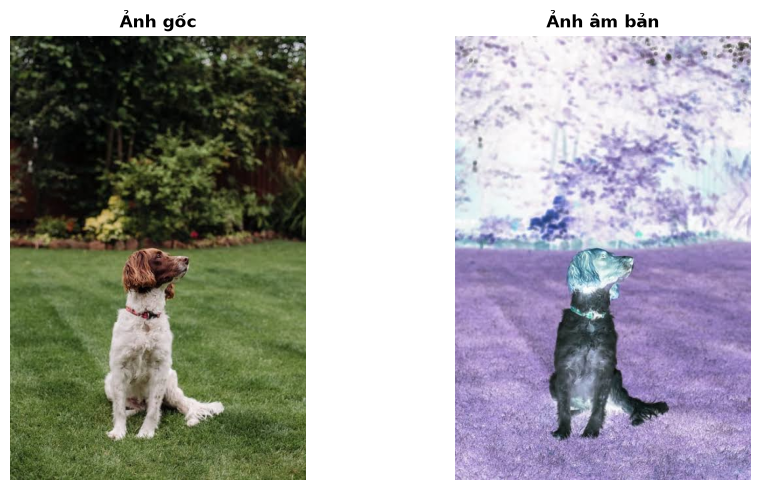

In [4]:
def imgNative(img):
    """
    Thực hiện biến đổi âm bản cho ảnh xám hoặc ảnh màu.
        s = 255 - r
    Trong đó:
        r: Giá trị cường độ sáng của pixel ở ảnh gốc.
        s: Giá trị cường độ sáng của pixel sau khi biến đổi.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (có thể là ảnh xám 2D hoặc ảnh màu RGB/BGR 3D).
        
    Returns:
        np.ndarray: Ảnh âm bản sau khi đảo ngược giá trị pixel (kiểu uint8).
    """
    # Lấy 255 trừ đi ma trận ảnh gốc
    return 255-img

images_list = [
    imgRGB,
    imgNative(imgRGB)
]
titles_list = [
    "Ảnh gốc",
    "Ảnh âm bản"
]
displayIMG(titles_list, images_list, 10, 5)

### 9. Đánh giá thực nghiệm

Đối chiếu vùng sáng/tối giữa hai ảnh: các mức cường độ đảo thứ tự. Đây là thay đổi biểu diễn, không phải phục hồi ảnh.

## 4. Cắt ngưỡng (Thresholding)

### 1. Vấn đề cần giải quyết
Cần tách đối tượng khỏi nền khi chúng có cường độ khác nhau.

### 2. Kiến thức nền tảng
Ảnh xám, histogram, phân đoạn ảnh và ngưỡng quyết định T.

### 3. Định nghĩa và bản chất
Global binary thresholding ánh xạ mỗi pixel vào một trong hai mức 0 và 255; đây là toán tử phi tuyến.

### 4. Lý do lựa chọn
Tạo mặt nạ đơn giản khi phân bố cường độ đối tượng và nền đủ tách biệt.

### 5. Nguyên lý và luồng xử lý
$$g(x,y)=\begin{cases}0 & f(x,y)<T\\255 & f(x,y)\ge T\end{cases}$$
Ví dụ với T=128, các giá trị 60, 128, 200 thành 0, 255, 255.

**Input:** ảnh xám 2D, T. **Process:** sao chép ảnh, gán theo điều kiện Boolean. **Output:** ảnh nhị phân uint8.

### 6. Ứng dụng và điều kiện sử dụng
Phân đoạn tài liệu, tạo mặt nạ đối tượng khi ánh sáng tương đối đồng đều. Ngưỡng không bảo đảm loại bỏ nhiễu; ảnh nhị phân uint8 không tự giảm bộ nhớ.

### 8. Triển khai

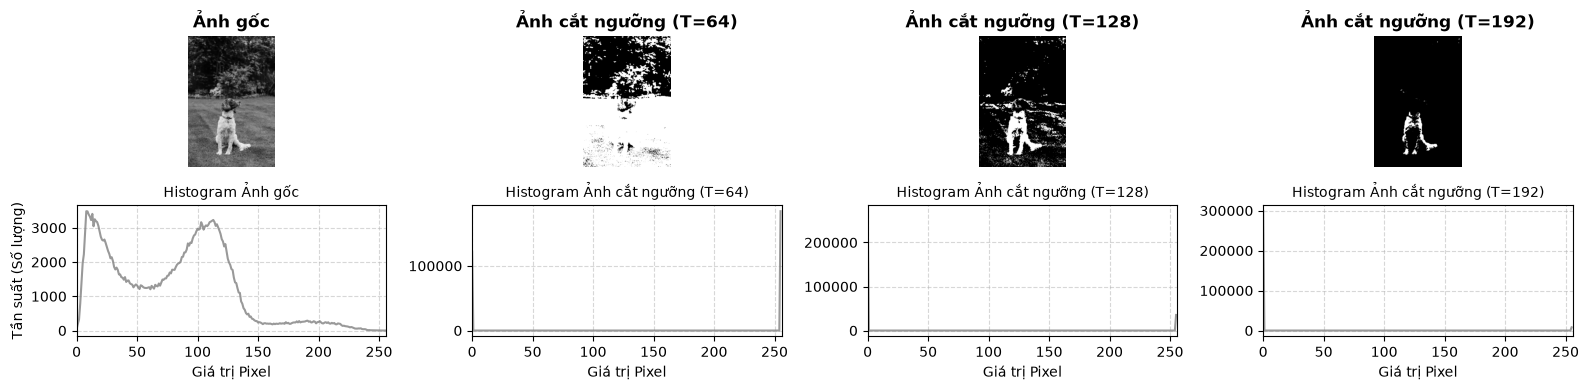

In [ ]:
def imgBinary(img, threshold=128):
    """
    Thực hiện cắt ngưỡng nhị phân hóa (Binary Thresholding) trên ảnh xám.
    
    Lý do cần đầu vào Grayscale:
        Phép cắt ngưỡng chỉ dựa trên một chiều cường độ sáng (intensity) duy nhất. 
        Nếu dùng ảnh màu 3 kênh (RGB), việc cắt ngưỡng độc lập trên từng kênh sẽ 
        làm biến dạng màu sắc và không tạo ra ảnh nhị phân đen/trắng thuần túy.
    
    Args:
        imgGray (np.ndarray): Ảnh đầu vào (Bắt buộc phải là ảnh xám 2D - Grayscale).
        threshold (int): Giá trị ngưỡng phân chia, từ 0 đến 255 (mặc định là 128).
        
    Returns:
        np.ndarray: Ảnh nhị phân kết quả, chỉ chứa đúng 2 giá trị 0 (Đen) và 255 (Trắng).
    """
    if len(img.shape) != 2:
        print("[Cảnh báo] Đầu vào ảnh nên là kênh màu Grayscale vì kênh màu khác có thể làm biến đổi màu sắc và không phù hợp với mục đích ảnh nhị phân!")
        return None
    elif threshold <= 0 or threshold >= 255:
        print("Giá trị cắt ngưỡng cần nằm trong [0,255] để được ảnh nhị phân")
    # Tạo bản sao để tránh làm thay đổi ảnh gốc
    img_binary = img.copy()
    
    # Các pixel nhỏ hơn ngưỡng chuyển thành 0 (Đen)
    img_binary[img_binary < threshold] = 0
    
    # Các pixel lớn hơn hoặc bằng ngưỡng chuyển thành 255 (Trắng)
    img_binary[img_binary >= threshold] = 255
    
    return img_binary

titles_list = [
    "Ảnh gốc",
    "Ảnh cắt ngưỡng (T=64)",
    "Ảnh cắt ngưỡng (T=128)",
    "Ảnh cắt ngưỡng (T=192)"
]
images_list = [
    imgGray,
    imgBinary(imgGray, threshold=64),
    imgBinary(imgGray),
    imgBinary(imgGray, threshold=192)
]

displayIMG(titles_list, images_list, 16, 4, forceGray=True)

### 9. Đánh giá thực nghiệm

So sánh T=64,128,192: khi T tăng, tập pixel trắng không thể tăng. Đánh giá hình dạng đối tượng và nền; chưa có mặt nạ ground truth để đo độ chính xác phân đoạn.

## II. LỌC TUYẾN TÍNH (LINEAR SPATIAL FILTERING)

## 1. Lọc trung bình (Mean Filter)

### 1. Vấn đề cần giải quyết
Nhiễu và biến thiên cục bộ làm ảnh thiếu ổn định; cần làm mượt bằng thông tin vùng lân cận.

### 2. Kiến thức nền tảng
Neighborhood, kernel, anchor và padding. Phép lọc tuyến tính lý tưởng thỏa tính cộng và đồng nhất. Tương quan chéo dùng $g(x,y)=\sum_{i,j}K(i,j)f(x+i,y+j)$; tích chập dùng $f(x-i,y-j)$. Kernel đối xứng cho hai kết quả giống nhau. Tần số không gian cao biểu thị biến thiên nhanh, gồm cả nhiễu và biên.

### 3. Định nghĩa và bản chất
Mean là bộ lọc thông thấp với trọng số bằng nhau.

### 4. Lý do lựa chọn
Trung bình nhiều mẫu có thể giảm biến động nhiễu ngẫu nhiên, đặc biệt trong vùng đồng nhất.

### 5. Nguyên lý và luồng xử lý
$$g(x,y)=\frac{1}{wh}\sum_{(i,j)\in W}f(x+i,y+j)$$
Kernel 3×3 có mọi hệ số 1/9. Ví dụ tám pixel 100 và một pixel 190 cho trung bình 110. Tổng trọng số bằng 1 giữ giá trị vùng hằng (trước clipping và với xử lý biên phù hợp).

**Input:** ảnh, kích thước k, border. **Process:** trượt cửa sổ, lấy trung bình, xử lý biên. **Output:** ảnh làm mượt.
`BORDER_CONSTANT` điền hằng số; `REPLICATE` lặp pixel biên; `REFLECT` phản chiếu có lặp pixel biên; `DEFAULT` thường là `REFLECT_101` không lặp pixel biên.

### 6. Ứng dụng và điều kiện sử dụng
Làm mượt nhanh, giảm nhiễu nhẹ. Kernel lớn thường làm mờ mạnh hơn; kích thước lẻ thuận tiện cho tâm đối xứng nhưng Mean không bắt buộc lẻ.

### 8. Triển khai

Kích thước kernel k phải là số nguyên dương lớn hơn 0.


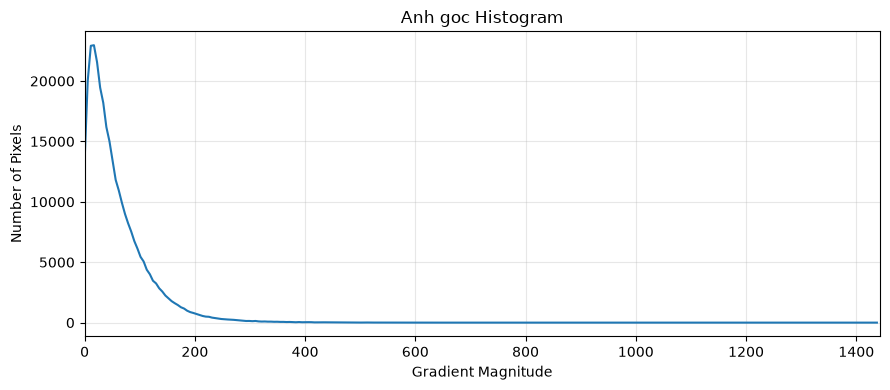

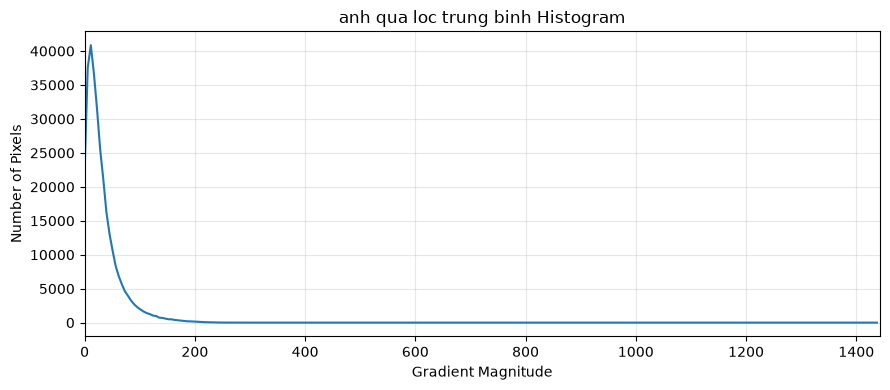

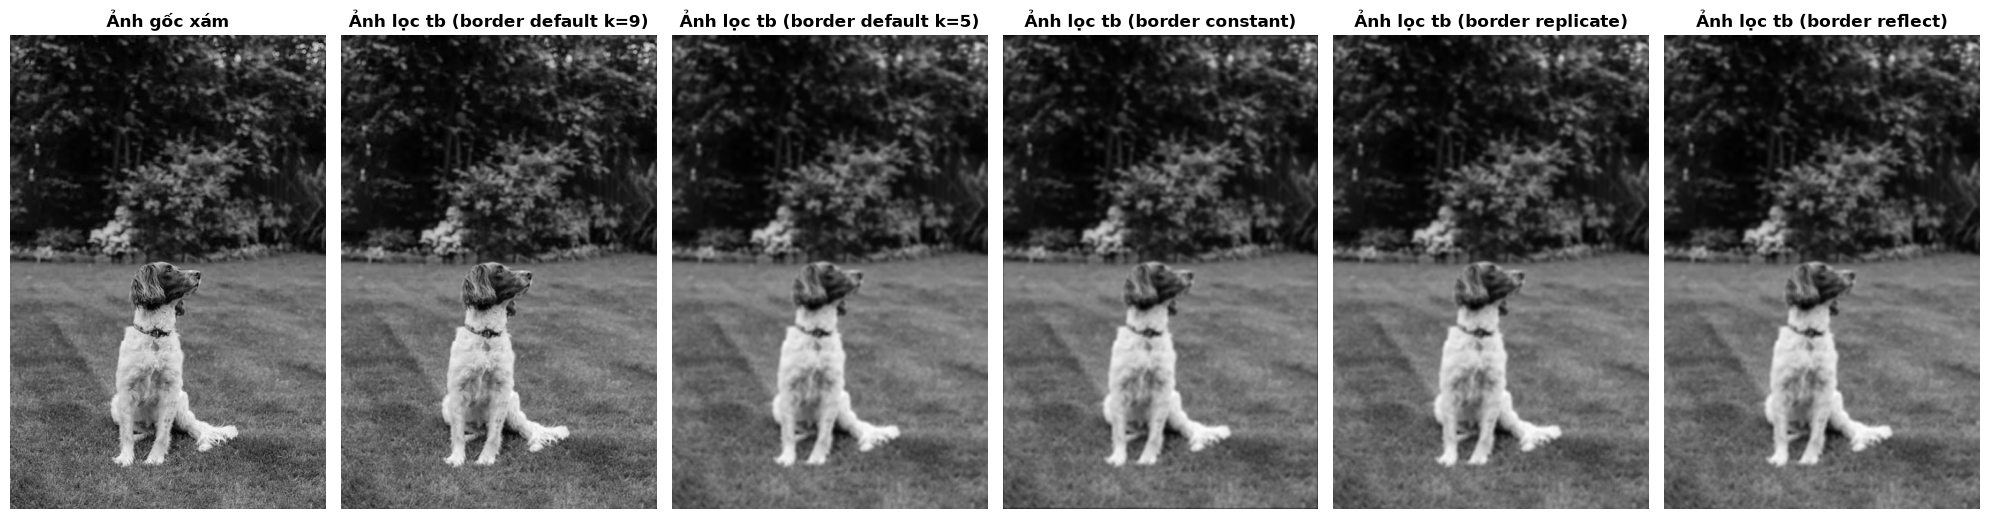

In [11]:
def filterMean(img, k, border = cv2.BORDER_DEFAULT):
  """
 Thực hiện lọc trung bình (Mean Filter) để làm mờ và khử nhiễu.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        k: kích thước kernel
        border: cách xử lý pixel biên của ảnh
        
    Returns:
        np.ndarray: Ảnh sau khi được làm mờ qua bộ lọc trung bình kích thước k.
  """
  # Kiểm tra k <=0 vì kích thước 1 kernel không <=0
  if k <= 0:
    print("[Cảnh báo] kích thước cần > 0!")
    return None 
  # Tránh hiện tượng dịch chuyển không gian với k chẵn
  elif k%2 == 0:
    print("Kích thước kernel k phải là số nguyên dương lớn hơn 0.")
  return cv2.blur(img, (k,k), borderType = border)

images_list = [
  imgGray,
  filterMean(imgGray, 2, cv2.BORDER_DEFAULT),
  filterMean(imgGray, 5, cv2.BORDER_DEFAULT),
  filterMean(imgGray, 5, cv2.BORDER_CONSTANT),
  filterMean(imgGray, 5, cv2.BORDER_REPLICATE),
  filterMean(imgGray, 5, cv2.BORDER_REFLECT)
]

titles_list = [
  "Ảnh gốc xám",
  "Ảnh lọc tb (border default k=9)",
  "Ảnh lọc tb (border default k=5)",
  "Ảnh lọc tb (border constant)",
  "Ảnh lọc tb (border replicate)",
  "Ảnh lọc tb (border reflect)"
]
show_gradient_histogram(imgGray, "Anh goc")
show_gradient_histogram(filterMean(imgGray, 5, cv2.BORDER_DEFAULT), "anh qua loc trung binh")

displayIMG(titles_list, images_list, 20, 8, forceGray=True)

### 9. Đánh giá thực nghiệm

So sánh histogram gradient ảnh gốc và ảnh lọc k=5; kỳ vọng giảm đáp ứng gradient mạnh ở nhiều vùng. Quan sát biên ảnh với từng padding. Lưu ý tiêu đề k=9 trong code thực tế gọi k=2; không dùng nhãn đó để kết luận về k=9.

## 2. Lọc Gaussian

### 1. Vấn đề cần giải quyết
Mean cho mọi pixel cùng trọng số; cần làm mượt ưu tiên thông tin gần pixel tâm.

### 2. Kiến thức nền tảng
Weighted average, phân phối Gaussian, độ lệch chuẩn sigma và chuẩn hóa kernel.

### 3. Định nghĩa và bản chất
Gaussian là bộ lọc tuyến tính thông thấp với trọng số giảm theo khoảng cách đến tâm.

### 4. Lý do lựa chọn
Trọng số gần tâm lớn giúp làm mượt có tính cục bộ; mức làm mờ điều khiển qua sigma và kích thước kernel.

### 5. Nguyên lý và luồng xử lý
$$G(i,j)=\frac{1}{2\pi\sigma^2}e^{-(i^2+j^2)/(2\sigma^2)},\qquad K(i,j)=\frac{G(i,j)}{\sum_W G}$$
Ví dụ kernel xấp xỉ 3×3: $\frac1{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$. Gaussian tách được thành hai phép lọc 1D theo X và Y.

**Input:** ảnh, k, sigma, border. **Process:** tạo trọng số, chuẩn hóa, lọc. **Output:** ảnh làm mượt.

### 6. Ứng dụng và điều kiện sử dụng
Khử nhiễu ngẫu nhiên nhẹ, tiền xử lý phát hiện biên. Sigma lớn thường làm mượt mạnh hơn với cửa sổ đủ rộng.

### 8. Triển khai

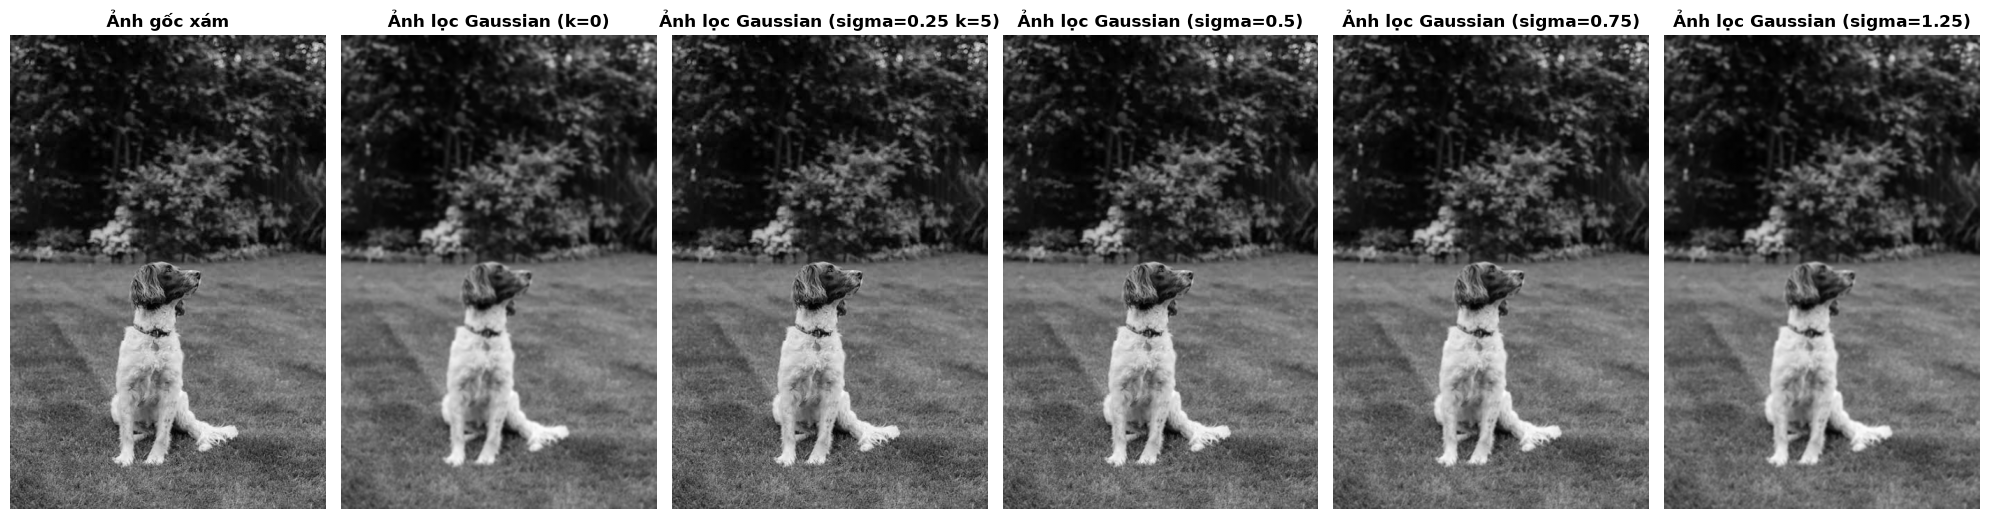

In [ ]:
def filterGaussian(img, k, sigma, border = cv2.BORDER_DEFAULT):
  """
    Thực hiện lọc Gaussian để làm mờ và khử nhiễu tự nhiên.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        k (int): Kích thước kernel (khuyến nghị số lẻ, vd: 3, 5, 7).
        sigma (float): Độ lệch chuẩn của phân phối Gaussian.
        
    Returns:
        np.ndarray: Ảnh sau khi qua bộ lọc Gaussian.
  """
  # chỉ kiểm tra chẵn lẻ mà không cần kiểm tra <=0 vì trong cv2.GaussianBlur có k=0 để tự động tính k theo sigma phù hợp và các giá trị âm sẽ được đưa về
  if k != 0:
    if k%2==0:
      print("[Cảnh báo] Kích thước kernel cần lẻ và lớn hơn 0!")
      return None
  
  return cv2.GaussianBlur(img, (k,k), sigma, borderType = border)

images_list = [
  imgGray,
  filterGaussian(imgGray, 0, 1.25),
  filterGaussian(imgGray, 5, 0.25),
  filterGaussian(imgGray, 5, 0.5),
  filterGaussian(imgGray, 5, 0.75),
  filterGaussian(imgGray, 5, 1.25)
]

titles_list = [
  "Ảnh gốc xám",
  "Ảnh lọc Gaussian (k=0)",
  "Ảnh lọc Gaussian (sigma=0.25 k=5)",
  "Ảnh lọc Gaussian (sigma=0.5)",
  "Ảnh lọc Gaussian (sigma=0.75)",
  "Ảnh lọc Gaussian (sigma=1.25)"
]

displayIMG(titles_list, images_list, 20, 8, forceGray=True)

### 9. Đánh giá thực nghiệm

So sánh các sigma với k=5 và trường hợp k tự động. Kỳ vọng sigma tăng làm mượt mạnh hơn trong điều kiện phù hợp. Không kết luận Gaussian luôn giữ biên tốt hơn Mean nếu chưa đối chiếu mức làm mượt tương đương.

## 3. Làm sắc nét (Sharpening)

### 1. Vấn đề cần giải quyết
Ảnh thiếu độ sắc nét khiến đường biên và chi tiết nhỏ khó quan sát.

### 2. Kiến thức nền tảng
Spatial frequency, đạo hàm bậc hai, kernel có trọng số âm và dương. Biên và nhiễu đều có thể chứa thành phần tần số cao.

### 3. Định nghĩa và bản chất
Sharpening tăng cường thành phần biến thiên nhanh trên nền ảnh gốc.

### 4. Lý do lựa chọn
Tăng độ nổi bật của cấu trúc và văn bản mà không chỉ xuất riêng ảnh biên.

### 5. Nguyên lý và luồng xử lý
$$K=\begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}$$
Kernel này tương ứng ảnh gốc trừ Laplacian với quy ước Laplacian tâm -4. Nếu tâm 100 và bốn láng giềng 80, kết quả là 180. Tổng kernel bằng 1 giữ vùng hằng; kernel tổng 0 chỉ lấy đáp ứng biến thiên.

**Input:** ảnh và kernel. **Process:** tương quan chéo, chuyển kết quả về kiểu ảnh đầu vào. **Output:** ảnh tăng cường chi tiết.

### 6. Ứng dụng và điều kiện sử dụng
Tăng khả năng quan sát văn bản và cấu trúc; không đồng nghĩa khôi phục chi tiết đã mất do mờ.

### 8. Triển khai

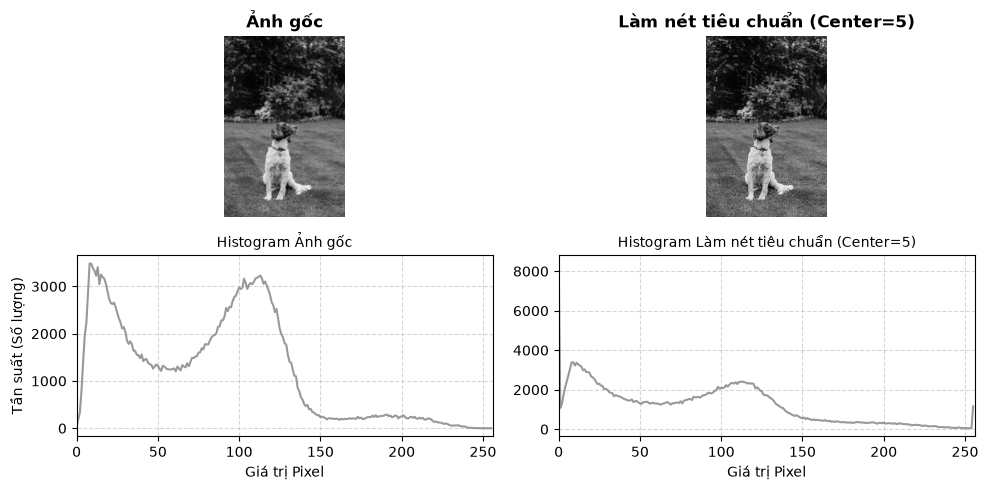

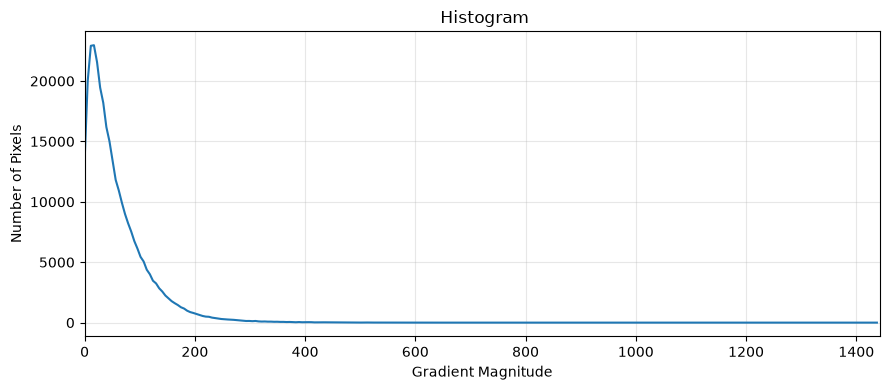

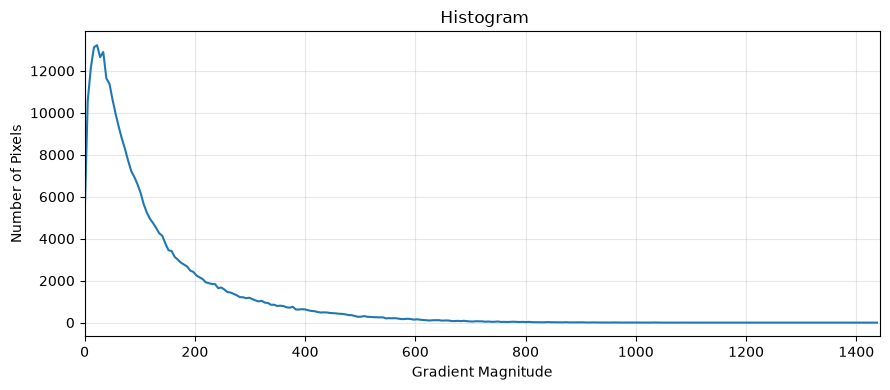

In [12]:
def filterSharpen(img, kernel=None):
    """
    Thực hiện làm nét ảnh bằng cách tự thiết kế Custom Kernel.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        kernel (np.ndarray, optional): Ma trận kernel tùy chỉnh dùng để làm nét. 
                                       Mặc định là None (sẽ tự động dùng kernel chuẩn 3x3 với trọng số làm nét tiêu chuẩn).
    Returns:
        np.ndarray: Ảnh sau khi được làm sắc nét.
    """
    if kernel is None:
        kernel = np.array([
            [0,-1,0],
            [-1,5,-1],
            [0,-1,0]
        ], dtype = np.float32)
    else:

        # KIỂM TRA TÍNH HỢP LỆ (INPUT VALIDATION)
        # Kiểm tra xem kernel có phải là mảng NumPy không
        if not isinstance(kernel, np.ndarray):
            print("[Cảnh báo] Kernel phải là một đối tượng numpy.ndarray!")
            return None

        # Kiểm tra số chiều (phải là ma trận 2D)
        if kernel.ndim != 2:
            print(f"[Cảnh báo] Kernel phải có 2 chiều (ndim=2), hiện tại là {kernel.ndim} chiều.")
            return None

        # Kiểm tra kích thước hàng và cột có phải là số lẻ không
        rows, cols = kernel.shape
        if rows % 2 == 0 or cols % 2 == 0:
            print(f"[Cảnh báo] Kích thước kernel phải là số lẻ (ví dụ 3x3, 5x5), hiện tại là {rows}x{cols}.")
            return None

        # Kiểm tra tổng các phần tử (Khuyến nghị tổng bằng 1.0 để bảo toàn độ sáng tổng thể của ảnh)
        kernel_sum = np.sum(kernel)
        if not np.isclose(kernel_sum, 1.0, atol=1e-5):
            print(f"[Cảnh báo] Tổng các phần tử của kernel hiện tại bằng {kernel_sum:.2f} (Khuyến nghị bằng 1.0 để giữ nguyên độ sáng ảnh).")
            return None

    # thực thi
    return cv2.filter2D(img, -1, kernel)


images_list = [
    imgGray,
    filterSharpen(imgGray)
]

titles_list = [
    "Ảnh gốc",
    "Làm nét tiêu chuẩn (Center=5)"
]

displayIMG(titles_list, images_list, 10, 5,True, True)
show_gradient_histogram(imgGray)
show_gradient_histogram(filterSharpen(imgGray))

### 9. Đánh giá thực nghiệm

Quan sát chi tiết và histogram gradient trước/sau lọc. Gradient mạnh có thể tăng do biên hoặc nhiễu; histogram không tự chứng minh chất lượng ảnh tốt hơn. Kiểm tra saturation ở ảnh uint8.

## III. BÀI TẬP NÂNG CAO

## 1. Phát hiện biên Sobel và Prewitt

### 1. Vấn đề cần giải quyết
Cần xác định vị trí thay đổi cường độ mạnh để nhận biết ranh giới và hình dạng.

### 2. Kiến thức nền tảng
Đạo hàm bậc nhất, sai phân hữu hạn, gradient magnitude và gradient direction.

### 3. Định nghĩa và bản chất
Sobel và Prewitt xấp xỉ hai thành phần đạo hàm không gian; Sobel dùng trọng số 1–2–1 theo phương làm mượt, Prewitt dùng 1–1–1.

### 4. Lý do lựa chọn
Đạo hàm phản hồi mạnh tại vùng biến thiên nhanh; hai thành phần giúp phát hiện biên nhiều hướng.

### 5. Nguyên lý và luồng xử lý
$$K_x^{S}=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\quad K_x^{P}=\begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix}$$
Kernel Y là chuyển vị của kernel X. $G_x$ phản hồi biên đứng, $G_y$ phản hồi biên ngang.
$$M=\sqrt{G_x^2+G_y^2},\qquad \theta=\operatorname{atan2}(G_y,G_x)$$
Hướng gradient vuông góc với đường biên lý tưởng. Ví dụ vùng 3×3 có mỗi hàng [20,20,80] cho Sobel X=240, Prewitt X=180, Y=0.

**Input:** ảnh xám. **Process:** tính đạo hàm có dấu bằng float, tính magnitude, chuyển kiểu để hiển thị. **Output:** ảnh đáp ứng biên.

### 6. Ứng dụng và điều kiện sử dụng
Trích xuất cấu trúc, tiền xử lý nhận dạng hình dạng. Không mặc định Sobel luôn tốt hơn Prewitt; cần xét nhiễu và thang đáp ứng.

### 8. Triển khai


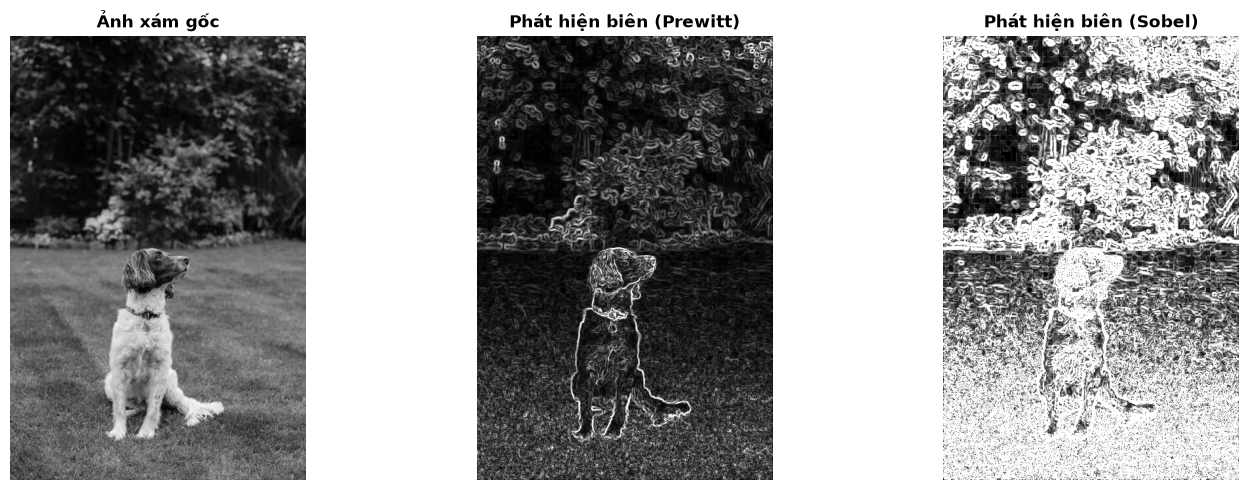

In [ ]:
def detectEdges(imgGray, method="sobel", ksize=3):
    """ 
    Phát hiện biên sử dụng toán tử Sobel hoặc Prewitt.
    
    Args:
        imgGray (np.ndarray): Ảnh đầu vào (bắt buộc là ảnh xám 2D).
        method (str): Phương pháp chọn ("sobel" hoặc "prewitt").
        ksize (int): Kích thước kernel (thường là 3).
        
    Returns:
        np.ndarray: Ảnh biên tổng hợp sau khi xử lý.
    """
    if imgGray.ndim != 2:
        print("[Cảnh báo] Đầu vào imgGray phải là ảnh xám 2D (Grayscale)!")
        return None
        
    method_lower = method.lower()
    if method_lower not in ["sobel", "prewitt"]:
        print(f"[Cảnh báo] Phương pháp '{method}' không hợp lệ! Chỉ hỗ trợ 'sobel' hoặc 'prewitt'.")
        return None
        
    # Kiểm tra ksize chung phải là số lẻ (hoặc -1 riêng cho Scharr)
    if ksize != -1 and (ksize <= 0 or ksize % 2 == 0):
        print(f"[Cảnh báo] Kích thước ksize = {ksize} không hợp lệ! Bắt buộc phải là số lẻ dương hoặc -1.")
        return None
    
    if method_lower == "sobel":
        # Sử dụng hàm tối ưu sẵn của OpenCV cho Sobel
        grad_x = cv2.Sobel(imgGray, cv2.CV_64F, 1, 0, ksize=-5)
        grad_y = cv2.Sobel(imgGray, cv2.CV_64F, 0, 1, ksize=-5)
        
    elif method_lower == "prewitt":
        # Tự thiết kế kernel Prewitt 3x3
        kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
        kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
                             
        grad_x = cv2.filter2D(imgGray, cv2.CV_64F, kernel_x)
        grad_y = cv2.filter2D(imgGray, cv2.CV_64F, kernel_y)
   

    # Tính biên độ gradient tổng hợp (Magnitude)
    magnitude = cv2.magnitude(grad_x, grad_y)
    
    # Chuẩn hóa về kiểu uint8 để hiển thị hình ảnh chuẩn
    edge_image = cv2.convertScaleAbs(magnitude)
    
    return edge_image

# --- Khối thực thi và so sánh trực quan ---
images_list = [
    imgGray,
    detectEdges(imgGray, method="prewitt"),
    detectEdges(imgGray, method="sobel")
]

titles_list = [
    "Ảnh xám gốc",
    "Phát hiện biên (Prewitt)",
    "Phát hiện biên (Sobel)"
]

displayIMG(titles_list, images_list, 15, 5, forceGray=True)

### 9. EVALUATION — Đánh giá thực nghiệm

So sánh vị trí biên thay vì chỉ độ sáng ảnh đáp ứng, vì hai kernel có thang khác nhau. Lời gọi Sobel ksize=-5 cần được xử lý trước khi xác nhận khả năng chạy lại; output cũ không chứng minh code hiện tại chạy đúng.

## 2. Tự thiết kế Kernel

### 1. Vấn đề cần giải quyết
Cần kiểm soát hiệu ứng lọc thay vì chỉ sử dụng bộ lọc có sẵn.

### 2. Kiến thức nền tảng
Ma trận trọng số, tương quan chéo, anchor, tổng trọng số (DC gain), tính đối xứng và hướng của kernel.

### 3. Định nghĩa và bản chất
Custom kernel xác định một phép lọc tuyến tính cục bộ với trọng số cố định; không đại diện cho mọi bộ lọc phi tuyến.

### 4. Lý do lựa chọn
Thay đổi trọng số và hình dạng cửa sổ giúp tạo hiệu ứng theo mục tiêu cụ thể.

### 5. Nguyên lý và luồng xử lý
$$g(x,y)=\sum_{i,j}K(i,j)f(x+i,y+j)$$
Tổng trọng số 1 giữ vùng hằng; tổng 0 triệt đáp ứng vùng hằng (với biên phù hợp). Kích thước lẻ giúp chọn tâm đối xứng nhưng không phải điều kiện bắt buộc của mọi kernel.

Bốn kernel trong code: Gaussian 3×3 chia 16; đường chéo 5×5 chia 5; sharpen tâm 5 với bốn trọng số -1; sharpen tâm 9 với tám trọng số -1.

**Input:** ảnh xám, ma trận kernel. **Process:** thiết kế trọng số, áp dụng `filter2D`. **Output:** ảnh với hiệu ứng tương ứng.

### 6. Ứng dụng và điều kiện sử dụng
Làm mờ theo hướng, tăng cường chi tiết hoặc thiết kế phép đo biến thiên theo yêu cầu.

### 8. Triển khai

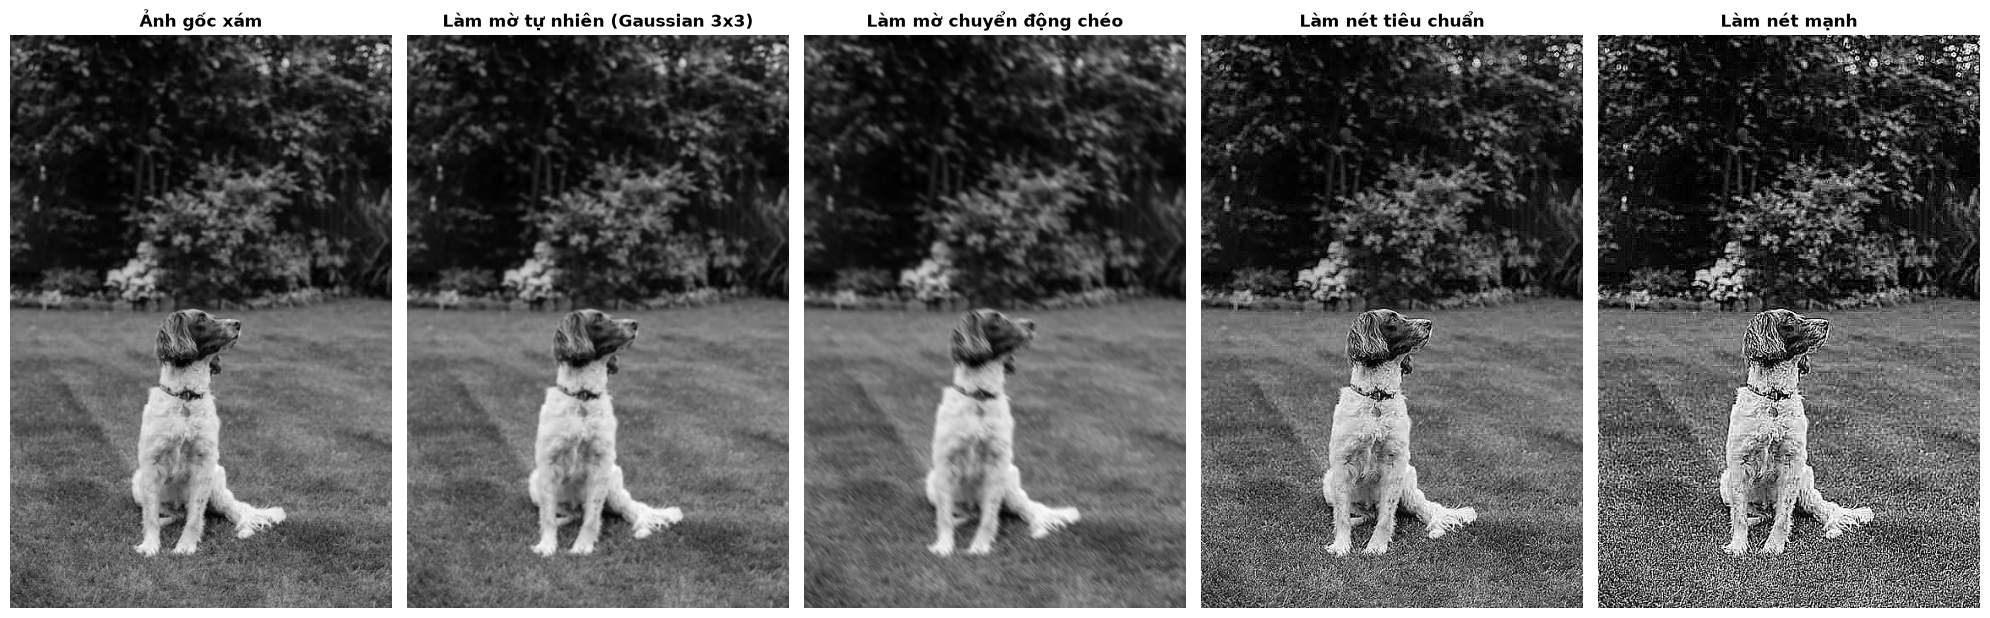

In [ ]:
def designKernelAndFilter(img):
    """
    Hàm thiết kế các Custom Kernel tùy chỉnh và trực quan hóa kết quả qua lưới 2x2.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (khuyến nghị ảnh xám 2D).
    """
    # 1. Kernel làm mờ tự nhiên (xấp xỉ phân phối Gaussian 3x3 bằng mảng số nguyên/hữu tỷ)
    kernel1 = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16.0

    # 2. Kernel làm mờ theo hướng chuyển động chéo (Directional Blur)
    kernel2 = np.array([
        [1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]
    ], dtype=np.float32) / 5.0

    # 3. Kernel làm nét tiêu chuẩn (Standard Sharpening)
    kernel3 = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32)

    # 4. Kernel làm nét mạnh (Strong Sharpening)
    kernel4 = np.array([
        [-1, -1, -1],
        [-1,  9, -1],
        [-1, -1, -1]
    ], dtype=np.float32)

    images_list =[
        img,
        cv2.filter2D(img, -1, kernel1),
        cv2.filter2D(img, -1, kernel2),
        cv2.filter2D(img, -1, kernel3),
        cv2.filter2D(img, -1, kernel4)
    ]
    titles_list = [
        "Ảnh gốc xám",
        "Làm mờ tự nhiên (Gaussian 3x3)",
        "Làm mờ chuyển động chéo",
        "Làm nét tiêu chuẩn",
        "Làm nét mạnh"
    ]

    displayIMG(titles_list, images_list, 20, 8, forceGray=True)

# Gọi hàm thực thi với ảnh xám 
designKernelAndFilter(imgGray)

### 9. EVALUATION — Đánh giá thực nghiệm

Đối chiếu Gaussian blur, directional blur và hai mức sharpen. Quan sát hướng mờ, độ nổi bật chi tiết và saturation; kernel tổng 1 không bảo đảm mọi pixel giữ nguyên độ sáng.

## 3–4. So sánh bộ lọc và lọc phi tuyến (Median, Bilateral)

### 1. PROBLEM — Vấn đề cần giải quyết
Cần chọn bộ lọc phù hợp với loại nhiễu, đồng thời duy trì cấu trúc ảnh.

### 2. FUNDAMENTALS — Kiến thức nền tảng
Gaussian noise là nhiễu cộng $n$ có phân phối chuẩn; salt-and-pepper thay thế pixel bằng 0 hoặc 255. Mean nhạy với ngoại lệ; median là thống kê thứ tự. Ground truth là ảnh sạch dùng làm tham chiếu.

### 3. WHAT — Định nghĩa và bản chất
Median lấy trung vị vùng lân cận. Bilateral lấy trung bình có trọng số phụ thuộc cả khoảng cách không gian và chênh lệch cường độ; cả hai là phi tuyến.

### 4. WHY — Lý do lựa chọn
Median giảm ảnh hưởng của ngoại lệ; Bilateral giảm trộn pixel khác cường độ qua biên. Mean và Gaussian là đối chứng tuyến tính.

### 5. HOW — Nguyên lý và luồng xử lý
$$g(p)=\operatorname{median}_{q\in W_p}I(q)$$
Ví dụ [98,99,100,100,101,102,102,103,255] có trung vị 101, trung bình khoảng 117.8.
$$g(p)=\frac{\sum_q w(p,q)I(q)}{\sum_q w(p,q)},\quad w(p,q)=e^{-\|p-q\|^2/(2\sigma_s^2)}e^{-|I(p)-I(q)|^2/(2\sigma_r^2)}$$
**Input:** ảnh sạch, loại nhiễu, tham số lọc. **Process:** tạo một ảnh nhiễu, áp dụng bốn bộ lọc lên cùng ảnh đó, so sánh với ảnh sạch. **Output:** ảnh lọc, histogram và chỉ số.

Với sai số $e_i=I_i-\hat I_i$ và N phần tử:
$$MSE=\frac1N\sum_i e_i^2,\quad MAE=\frac1N\sum_i|e_i|,\quad PSNR=10\log_{10}\frac{255^2}{MSE}$$
$$SSIM=\frac{(2\mu_I\mu_J+C_1)(2\sigma_{IJ}+C_2)}{(\mu_I^2+\mu_J^2+C_1)(\sigma_I^2+\sigma_J^2+C_2)}$$
SSIM so sánh độ chói, tương phản và cấu trúc cục bộ; giá trị gần 1 biểu thị tương đồng cao. MSE/MAE thấp và PSNR cao là tốt hơn khi mục tiêu là khôi phục ảnh sạch.

### 6. WHERE & WHEN — Ứng dụng và điều kiện sử dụng
Median thường phù hợp nhiễu xung; Gaussian thường phù hợp nhiễu cộng nhẹ; Bilateral hữu ích khi cần làm mượt giữ biên. Hiệu quả phụ thuộc ảnh và tham số.

### 8. IMPLEMENTATION — Triển khai
`compareFilter()` dùng Mean 5×5, Gaussian 5×5 sigma 0.85, Median 5, Bilateral d=9 sigmaColor=75 sigmaSpace=75. Nhiễu Gaussian có variance 25 (sigma=5); salt-and-pepper dùng ratio=0.1 nhưng tọa độ có thể trùng. Code giữ nguyên.

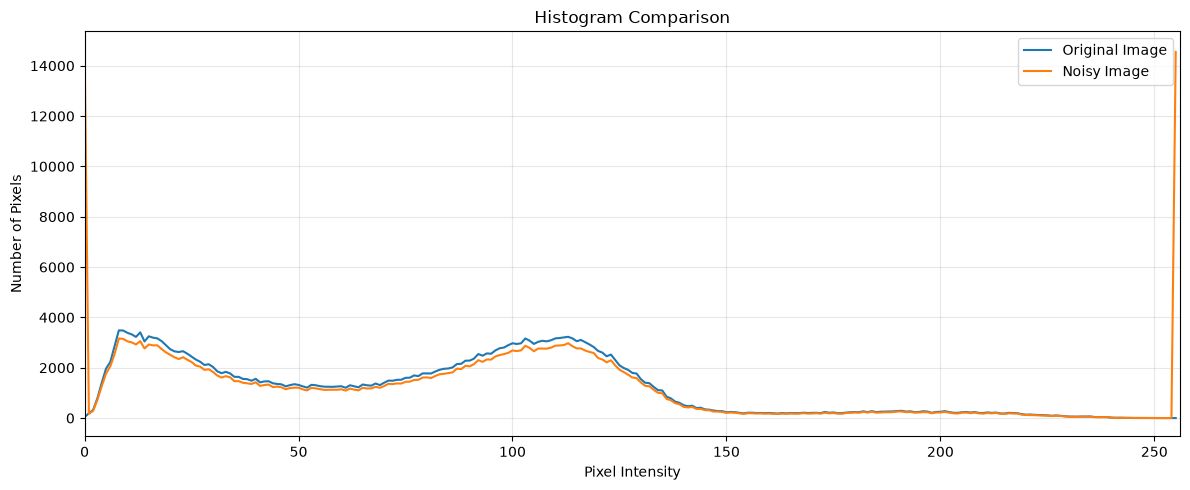


--- Mean Filter ---
MSE: 211.2736, MAE: 10.9802, PSNR: 24.8824 dB, SSIM: 0.5864

--- Gaussian Filter ---
MSE: 294.9279, MAE: 11.1358, PSNR: 23.4336 dB, SSIM: 0.5204

--- Median Filter ---
MSE: 77.9355, MAE: 5.1815, PSNR: 29.2135 dB, SSIM: 0.8182

--- Bilateral Filter ---
MSE: 950.4344, MAE: 11.9267, PSNR: 18.3516 dB, SSIM: 0.3374


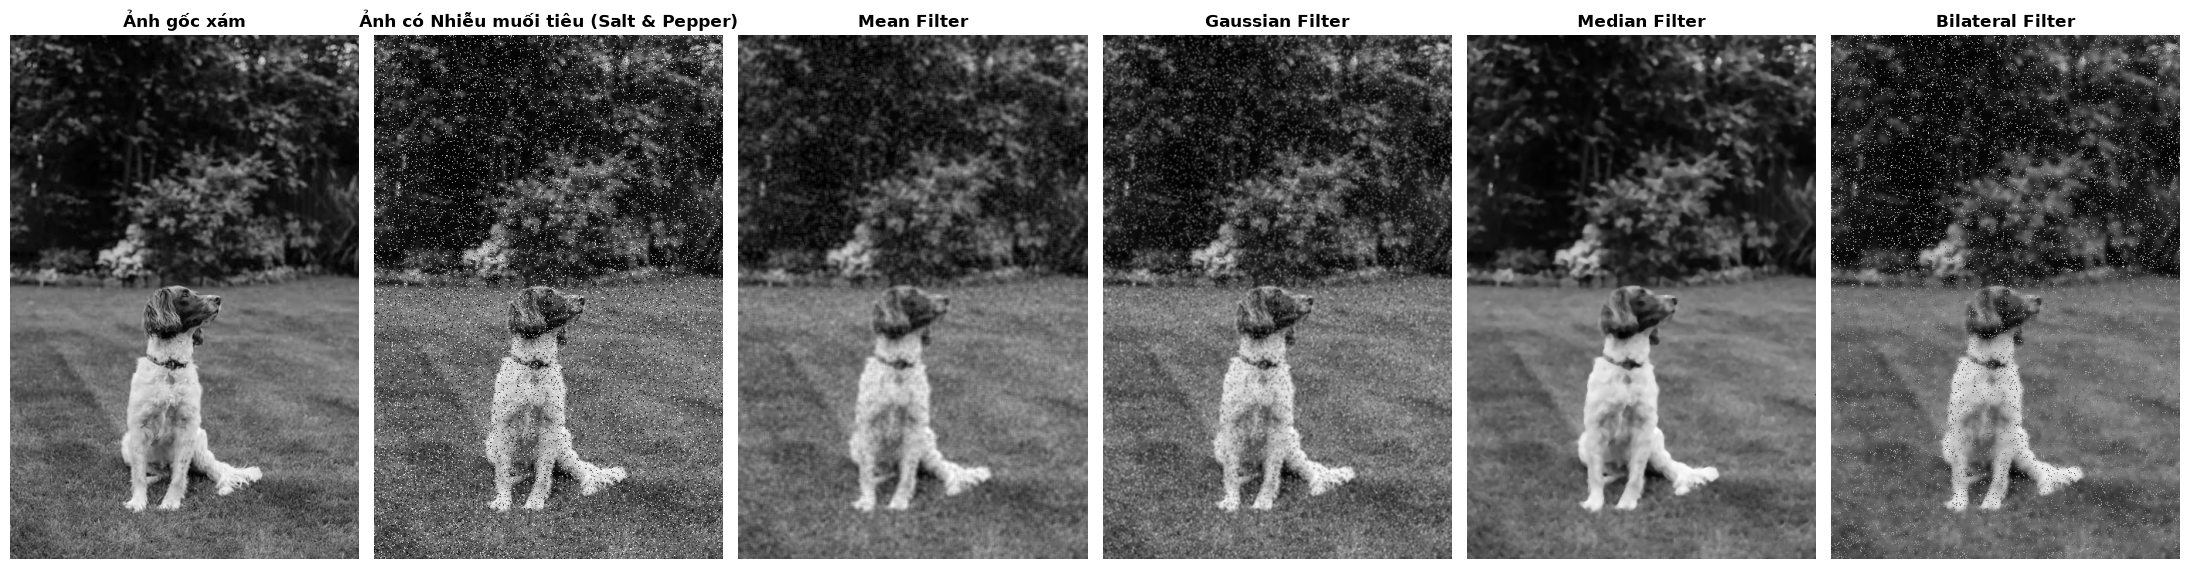

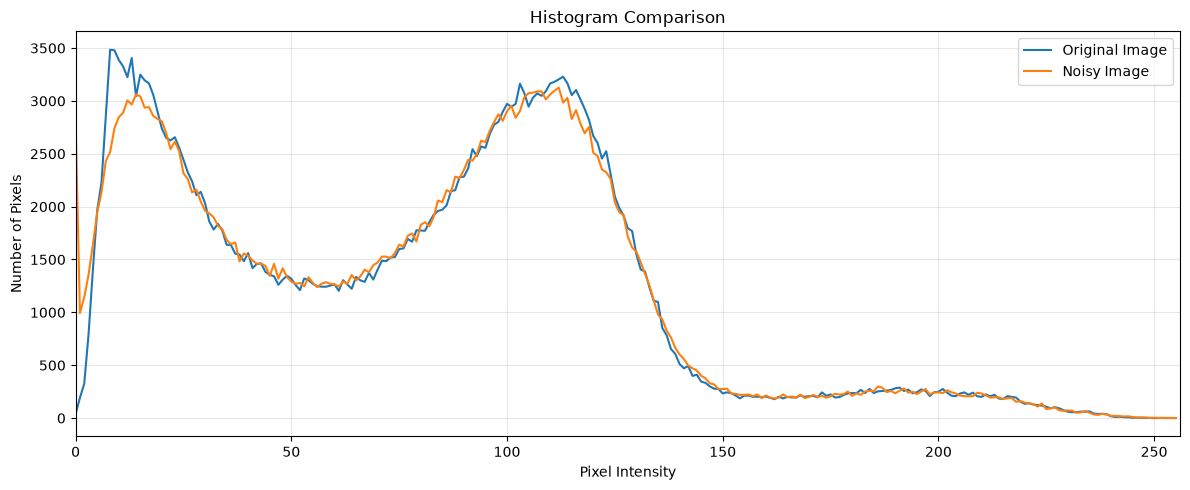


--- Mean Filter ---
MSE: 83.5868, MAE: 5.8150, PSNR: 28.9094 dB, SSIM: 0.8046

--- Gaussian Filter ---
MSE: 32.9969, MAE: 3.6388, PSNR: 32.9461 dB, SSIM: 0.9232

--- Median Filter ---
MSE: 77.3823, MAE: 5.4937, PSNR: 29.2444 dB, SSIM: 0.8115

--- Bilateral Filter ---
MSE: 95.2792, MAE: 6.6942, PSNR: 28.3408 dB, SSIM: 0.7527


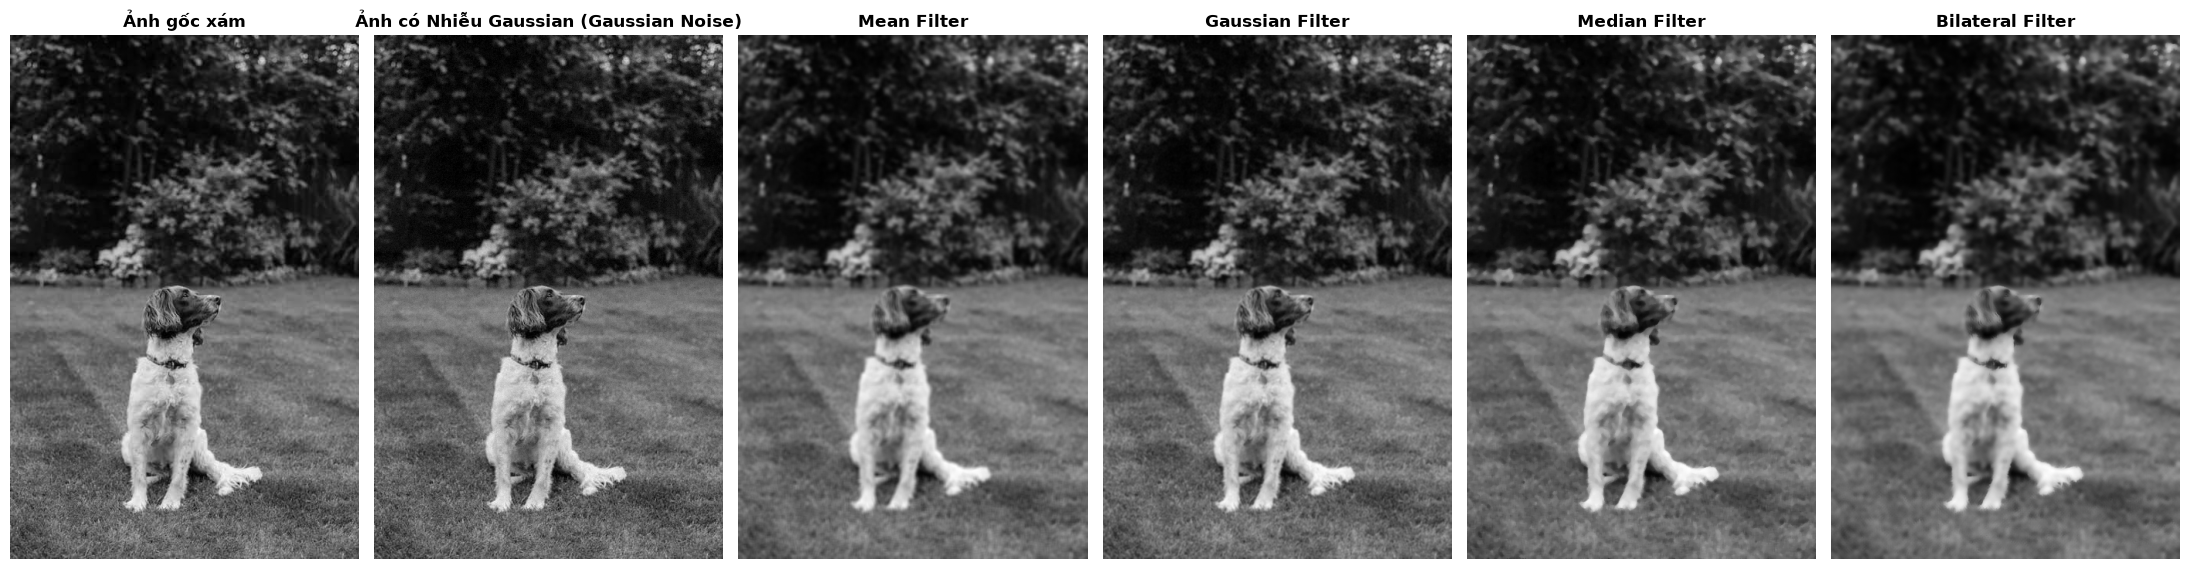

In [ ]:
def addGaussianNoise(img, mean=0, var=25):
    """
    Thêm nhiễu Gauss (Additive Gaussian Noise) vào ảnh.
    
    Args:
        img (np.ndarray): Ảnh đầu vào.
        mean (float): Giá trị trung bình của nhiễu.
        var (float): Phương sai (variance) của nhiễu.
    Returns:
        np.ndarray: Ảnh sau khi đã được gán nhiễu.
    """
    sigma = var ** 0.5
    gaussian_noise = np.random.normal(mean, sigma, img.shape)
    imgNoisy = img.astype(np.float32) + gaussian_noise
    # Giới hạn giá trị pixel trong khoảng [0, 255] và chuyển về uint8
    imgNoisy = np.clip(imgNoisy, 0, 255).astype(np.uint8)
    return imgNoisy

def addSaltNoise(img, ratio = 0.1):
    """
        Thêm nhiễu muối tiêu (Salt-and-Pepper Noise) vào ảnh với tỷ lệ tùy chỉnh.
        
        Args:
            img (np.ndarray): Ảnh đầu vào.
            ratio (float): Tỷ lệ pixel bị nhiễu so với tổng số pixel (mặc định là 0.01 tương đương 1%).
                           Ví dụ: 0.02 là 2%, 0.05 là 5%.
            
        Returns:
            np.ndarray: Ảnh sau khi đã được gán nhiễu.
    """
    # Tính số lượng điểm nhiễu dựa trên tổng số pixel
    numNoise = int(img.size * ratio)
    imgNoisy = img.copy()

    # Thêm ngẫu nhiên các điểm nhiễu trắng (255) hoặc đen (0)
    for _ in range(numNoise):
        yCoord = np.random.randint(0, img.shape[0])
        xCoord = np.random.randint(0, img.shape[1])
        imgNoisy[yCoord, xCoord] = 255 if np.random.rand() > 0.5 else 0

    return imgNoisy

def calculate_metrics(
    image,
    filtered_image
):
    """
    Tính toán các chỉ số đánh giá giữa ảnh gốc và ảnh sau lọc.

    Args:
        image: Ảnh gốc không nhiễu.
        filtered_image: Ảnh thu được sau khi áp dụng bộ lọc.
            Hai ảnh phải có cùng kích thước và số kênh.

    Returns:
        Dictionary chứa bốn chỉ số đánh giá:
            - MSE: Sai số bình phương trung bình.
            - MAE: Sai số tuyệt đối trung bình.
            - PSNR: Tỷ số tín hiệu trên nhiễu cực đại (dB).
            - SSIM: Chỉ số tương đồng cấu trúc.

    Raises:
        TypeError: Nếu dữ liệu ảnh không đúng kiểu dữ liệu yêu cầu.
        ValueError: Nếu ảnh không hợp lệ hoặc hai ảnh khác kích thước,
            số kênh.
    Notes:
        Gọi N là tổng số pixel trên tất cả các kênh ảnh.
        I(i) là giá trị pixel thứ i của ảnh tham chiếu.
        K(i) là giá trị pixel thứ i của ảnh sau lọc.

        1. Sai số bình phương trung bình (MSE):

            MSE = (1/N) * SUM((I(i) - K(i))^2)

        2. Sai số tuyệt đối trung bình (MAE):

            MAE = (1/N) * SUM(|I(i) - K(i)|)

        3. Tỷ số tín hiệu trên nhiễu cực đại (PSNR):

            PSNR = 10 * log10(MAX^2 / MSE)

        Trong đó:
            - MAX = 255 đối với ảnh uint8.
            - SUM biểu thị tổng sai số trên toàn bộ pixel.
            - log10 là logarit cơ số 10.

        Nếu MSE = 0, hai ảnh giống hệt nhau và PSNR = vô cực.

        Ảnh được chuyển sang kiểu float64 trước khi tính toán
        nhằm tránh hiện tượng tràn số trong phép tính.
        SSMI: Dựa trên cấu trúc tổng thể và cách thị giác con người (HVS) hoạt động. Thay vì soi từng pixel đơn lẻ, SSIM chia bức ảnh thành các vùng nhỏ và so sánh 3 yếu tố cốt lõi:
        Độ chói (Luminance): So sánh độ sáng chung.
        Độ tương phản (Contrast): So sánh độ chênh lệch sáng tối.
        Cấu trúc (Structure): So sánh các đường nét, hình khối, biên độ.
    """
    if image.shape != filtered_image.shape:
        raise ValueError(
            "Hai ảnh phải có cùng kích thước và số kênh."
        )

    # Chuyển sang float64 để tránh tràn số cho các tính toán toán học thô
    img = image.astype(np.float64)
    filtered = filtered_image.astype(np.float64)

    difference = img - filtered

    # 1. Mean Squared Error (MSE)
    mse = float(np.mean(difference ** 2))

    # 2. Mean Absolute Error (MAE)
    mae = float(np.mean(np.abs(difference)))

    # 3. Peak Signal-to-Noise Ratio (PSNR)
    if mse == 0:
        psnr = float("inf")
    else:
        psnr = float(
            10 * np.log10((255 ** 2) / mse)
        )

    # 4. Structural Similarity Index (SSIM)
    # Xử lý tự động cho cả ảnh xám (2D) và ảnh màu RGB (3D)
    if image.ndim == 3:
        ssim_val = float(ssim(img, filtered, data_range=255, channel_axis=-1))
    else:
        ssim_val = float(ssim(img, filtered, data_range=255))

    # In kết quả theo dõi
    print(f"MSE: {mse:.4f}, MAE: {mae:.4f}, PSNR: {psnr:.4f} dB, SSIM: {ssim_val:.4f}")

    
    
def compareFilter(img, typeNoise="salt"):
    """
    So sánh trực quan 4 bộ lọc không gian trên ảnh bị gán nhiễu nhân tạo.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (khuyến nghị ảnh xám 2D).
        typeNoise (str): Loại nhiễu ("salt" hoặc "gaussian").
    """
    # Tạo nhiễu tương ứng dựa theo loại người dùng yêu cầu
    if typeNoise.lower() == "salt":
        imgNoisy = addSaltNoise(img)
        noise_name = "Nhiễu muối tiêu (Salt & Pepper)"
    else:
        imgNoisy = addGaussianNoise(img, mean=0, var=25)
        noise_name = "Nhiễu Gaussian (Gaussian Noise)"
        
    # Thực thi 4 loại lọc trên cùng một ảnh có nhiễu
    images_list = [
        img,
        imgNoisy,                                      
        cv2.blur(imgNoisy, (5, 5)),
        cv2.GaussianBlur(imgNoisy, (5, 5), 0.85),
        cv2.medianBlur(imgNoisy, 5),
        cv2.bilateralFilter(imgNoisy, 9, 75, 75)
    ]


    titles_list = [
        "Ảnh gốc xám",
        f"Ảnh có {noise_name}",
        "Mean Filter",
        "Gaussian Filter",
        "Median Filter",
        "Bilateral Filter"
    ]
   
    hist_original = cv2.calcHist(
       [img], [0], None, [256], [0, 256]
    )

    hist_noisy = cv2.calcHist(
        [imgNoisy], [0], None, [256], [0, 256]
    )

    # Vẽ Histogram
    plt.figure(figsize=(12, 5))

    plt.plot(hist_original, label="Original Image")
    plt.plot(hist_noisy, label="Noisy Image")

    plt.title("Histogram Comparison")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Number of Pixels")

    plt.xlim([0, 256])
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    for i in range(2, len(images_list)):
        print(f"\n--- {titles_list[i]} ---")
        calculate_metrics(img, images_list[i])
       
    # Hiển thị trực quan (Kiểm tra lại tên tham số force_gray / forceGray khớp với hàm gốc của em)
    displayIMG(titles_list, images_list, 22, 6, forceGray=True)

# --- Khối thực thi khảo sát ---
# 1. Khảo sát hiệu quả dưới tác động của Nhiễu muối tiêu
compareFilter(imgGray, typeNoise="salt")

# 2. Khảo sát hiệu quả dưới tác động của Nhiễu Gauss
compareFilter(imgGray, typeNoise="gaussian")

### 9. EVALUATION — Đánh giá thực nghiệm

So sánh MSE, MAE, PSNR và SSIM giữa bốn bộ lọc trên từng loại nhiễu. MSE và PSNR có quan hệ trực tiếp; không coi là hai bằng chứng độc lập. Để đánh giá mức cải thiện cần thêm baseline ảnh nhiễu so với ảnh sạch, cố định seed và khảo sát nhiều ảnh/tham số ở giai đoạn sau.